# SaludVital BI — Análisis exploratorio del modelo dimensional

Este notebook consume las tablas que genera `scripts/modelo_dimensional.py` (carpeta `data/modelo/`) y responde, con gráficos, las preguntas de negocio de la documentación (D1–D5, R1–R5, M1–M5, P1–P5 y RQ01–RQ24).

**Antes de ejecutar:** `python scripts/modelo_dimensional.py` y luego *Run All*.

**Definiciones** (idénticas a las medidas DAX del proyecto):
- *Tasa de atención* = Atendidas / (Atendidas + No asistió + Canceladas)
- *Tasa de inasistencia* = No asistió / (Atendidas + No asistió)
- *Tasa de cancelación* = Canceladas / (Atendidas + No asistió + Canceladas)
- *Ingreso* = Cantidad × ValorUnitario (**valorizado, no cobrado**; no existe fuente de pagos)

**Limitaciones del dato:** simulación (no es operación real); el canal y el bloque solo existen desde el 2026-02-04, por lo que utilización y horas perdidas se calculan solo sobre reservas con bloque; se usan IDs de paciente, nunca nombres.

## 0. Configuración y carga

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4), "figure.dpi": 110, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
})
pd.set_option("display.width", 160, "display.max_columns", 30)

def raiz_repo():
    p = Path.cwd().resolve()
    for c in [p, *p.parents]:
        if (c / "data" / "modelo").exists():
            return c
    raise FileNotFoundError("No existe data/modelo. Ejecuta primero: python scripts/modelo_dimensional.py")

MODELO = raiz_repo() / "data" / "modelo"

ESTADOS = ["Atendida", "No asistió", "Cancelada", "Pendiente"]
COL_EST = {"Atendida": "#2E7D6B", "No asistió": "#D1495B", "Cancelada": "#EDAE49", "Pendiente": "#8D99AE"}
ORDEN_DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
CANALES_OK = ["Recepción", "Teléfono", "Sitio web", "Aplicación móvil"]
AZUL, VERDE = "#3A6EA5", "#2E7D6B"

def clp(x):
    return "$" + f"{x:,.0f}".replace(",", ".")

def tasas(df, por):
    """Conteo por estado y tasas (definiciones DAX) agrupando por `por`."""
    t = df.pivot_table(index=por, columns="EstadoReserva", values="ReservaID",
                       aggfunc="count", fill_value=0).reindex(columns=ESTADOS, fill_value=0)
    t["Total"] = t[ESTADOS].sum(axis=1)
    resueltas = t["Atendida"] + t["No asistió"] + t["Cancelada"]
    t["Tasa atención"] = (t["Atendida"] / resueltas).replace([np.inf, -np.inf], np.nan)
    t["Tasa inasistencia"] = (t["No asistió"] / (t["Atendida"] + t["No asistió"])).replace([np.inf, -np.inf], np.nan)
    t["Tasa cancelación"] = (t["Cancelada"] / resueltas).replace([np.inf, -np.inf], np.nan)
    return t

def barras(ax, fmt="{:,.0f}"):
    for c in ax.containers:
        ax.bar_label(c, labels=[fmt.format(v) for v in c.datavalues], padding=2, fontsize=8)

In [2]:
fecha = pd.read_csv(MODELO / "DimFecha.csv", parse_dates=["Date"])
pac = pd.read_csv(MODELO / "DimPaciente.csv")
med = pd.read_csv(MODELO / "DimMedico.csv")
pre = pd.read_csv(MODELO / "DimPrestacion.csv")
hr_raw = pd.read_csv(MODELO / "HechoReservas.csv", parse_dates=["FechaReserva"])
hd_raw = pd.read_csv(MODELO / "HechoDetalle.csv", parse_dates=["FechaAtencion"])

cal = fecha[["Date", "AnioMes", "NombreDia", "Periodo"]]

# Hechos enriquecidos con sus dimensiones (uniones N:1, no multiplican filas)
hr = (hr_raw
      .merge(cal, left_on="FechaReserva", right_on="Date", how="left", validate="m:1")
      .merge(med[["MedicoID", "Medico", "Especialidad"]], on="MedicoID", how="left", validate="m:1")
      .merge(pac[["PacienteID", "Comuna", "Prevision", "Sexo"]], on="PacienteID", how="left", validate="m:1"))

hd = (hd_raw
      .merge(cal, left_on="FechaAtencion", right_on="Date", how="left", validate="m:1")
      .merge(med[["MedicoID", "Medico"]], on="MedicoID", how="left", validate="m:1")
      .merge(pre[["PrestacionID", "Prestacion", "Especialidad"]], on="PrestacionID", how="left", validate="m:1"))

assert len(hr) == len(hr_raw) and len(hd) == len(hd_raw), "Una unión duplicó filas"
print(f"HechoReservas: {len(hr)} filas | HechoDetalle: {len(hd)} filas")
print(f"Reservas del {hr.FechaReserva.min():%d-%m-%Y} al {hr.FechaReserva.max():%d-%m-%Y}")

HechoReservas: 75 filas | HechoDetalle: 41 filas
Reservas del 05-01-2026 al 28-02-2026


## 1. Panorama general (KPIs)

In [3]:
est = hr.EstadoReserva.value_counts().reindex(ESTADOS, fill_value=0)
resueltas = est[["Atendida", "No asistió", "Cancelada"]].sum()
kpis = pd.DataFrame({"Valor": {
    "Total de reservas": f"{len(hr):,}",
    "Atenciones realizadas": f"{hr.AtencionID.nunique():,}",
    "Tasa de atención": f"{est['Atendida'] / resueltas:.1%}",
    "Tasa de inasistencia": f"{est['No asistió'] / (est['Atendida'] + est['No asistió']):.1%}",
    "Tasa de cancelación": f"{est['Cancelada'] / resueltas:.1%}",
    "Reservas pendientes": f"{est['Pendiente']:,}",
    "Ingreso valorizado": clp(hd.Importe.sum()),
    "Ingreso promedio por atención": clp(hd.Importe.sum() / hd.AtencionID.nunique()),
    "Pacientes distintos (con reservas)": f"{hr.PacienteID.nunique():,}",
    "Médicos activos": f"{hr.MedicoID.nunique():,}",
}})
kpis

,Valor
Total de reservas,75
Atenciones realizadas,46
Tasa de atención,68.6%
Tasa de inasistencia,20.0%
Tasa de cancelación,14.3%
Reservas pendientes,5
Ingreso valorizado,$1.671.000
Ingreso promedio por atención,$40.756
Pacientes distintos (con reservas),44
Médicos activos,14


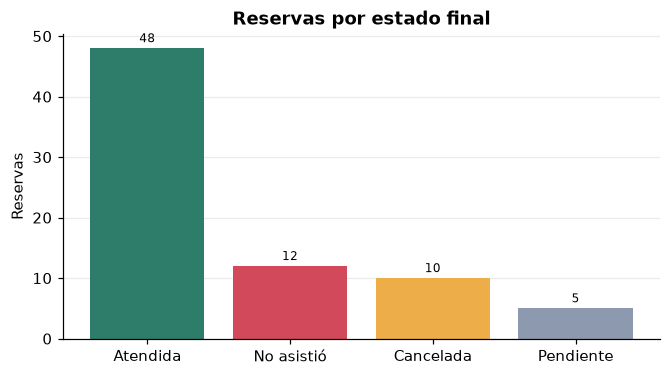

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(est.index, est.values, color=[COL_EST[e] for e in est.index])
barras(ax); ax.set(title="Reservas por estado final", ylabel="Reservas"); ax.grid(axis="x", visible=False)
plt.show()

## 2. Demanda (D1, D5, R3, RQ01–RQ04)

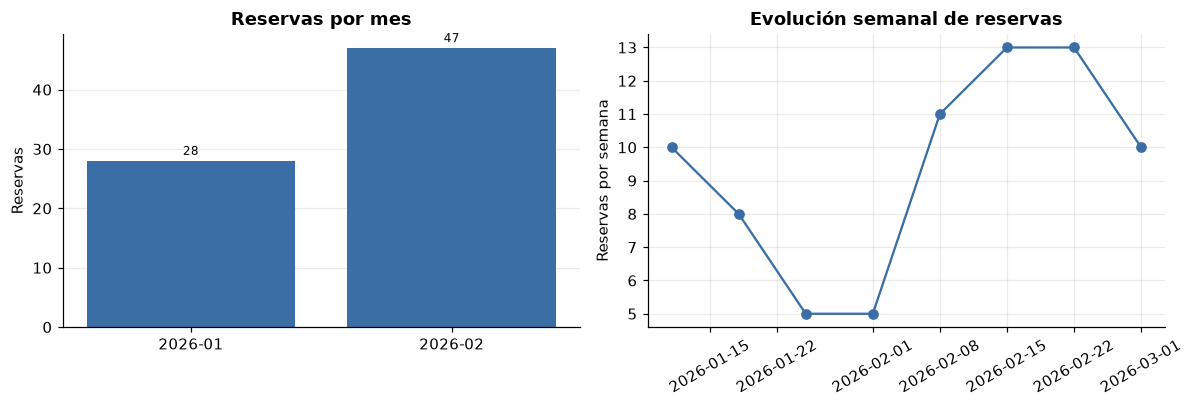

Nota: enero parte el día 5; el mes más reciente puede estar incompleto. Compara con la tasa por día (abajo).


In [5]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
m = hr.groupby("AnioMes").size()
axs[0].bar(m.index, m.values, color=AZUL); barras(axs[0])
axs[0].set(title="Reservas por mes", ylabel="Reservas"); axs[0].grid(axis="x", visible=False)

sem = hr.set_index("FechaReserva").resample("W-SUN").size()
axs[1].plot(sem.index, sem.values, marker="o", color=AZUL)
axs[1].set(title="Evolución semanal de reservas", ylabel="Reservas por semana")
axs[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
print("Nota: enero parte el día 5; el mes más reciente puede estar incompleto. Compara con la tasa por día (abajo).")

,Reservas,Desde,Hasta,Dias,Reservas por día
Periodo,,,,,
Adicional,45,2026-02-04,2026-02-28,25,1.8
Base,30,2026-01-05,2026-02-03,30,1.0


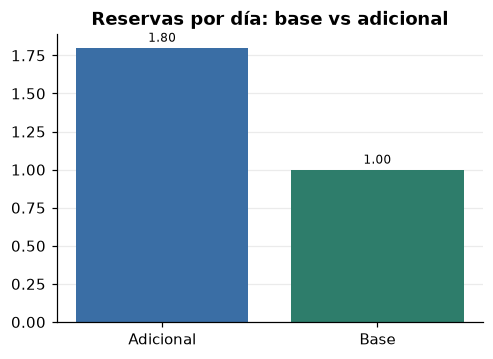

In [6]:
# D5: período base vs adicional (duran distinto, por eso se normaliza por día)
per = hr.groupby("Periodo").agg(Reservas=("ReservaID", "size"),
                                Desde=("FechaReserva", "min"), Hasta=("FechaReserva", "max"))
per["Dias"] = (per.Hasta - per.Desde).dt.days + 1
per["Reservas por día"] = (per.Reservas / per.Dias).round(2)
display(per)

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.bar(per.index, per["Reservas por día"], color=[AZUL, VERDE][:len(per)])
barras(ax, "{:.2f}"); ax.set(title="Reservas por día: base vs adicional"); ax.grid(axis="x", visible=False)
plt.show()

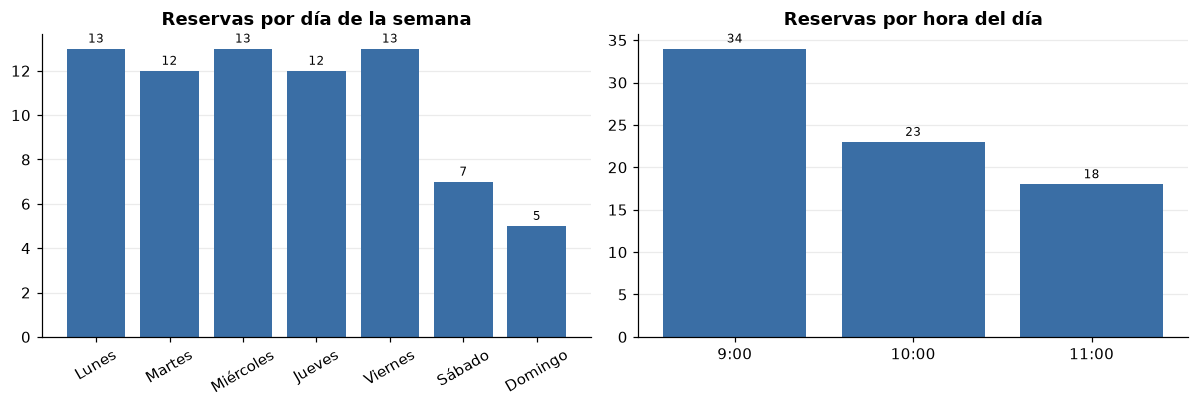

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
d = hr.groupby("NombreDia").size().reindex(ORDEN_DIAS, fill_value=0)
axs[0].bar(d.index, d.values, color=AZUL); barras(axs[0])
axs[0].set(title="Reservas por día de la semana"); axs[0].tick_params(axis="x", rotation=30)
axs[0].grid(axis="x", visible=False)

h = hr.groupby("HoraDia").size()
axs[1].bar(h.index.astype(str) + ":00", h.values, color=AZUL); barras(axs[1])
axs[1].set(title="Reservas por hora del día"); axs[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 3. Atención, inasistencia y cancelación (D4, R4, RQ05–RQ08)

EstadoReserva,Atendida,No asistió,Cancelada,Pendiente,Total,Tasa atención,Tasa inasistencia,Tasa cancelación
AnioMes,,,,,,,,
2026-01,20,4,4,0,28,71.4%,16.7%,14.3%
2026-02,28,8,6,5,47,66.7%,22.2%,14.3%


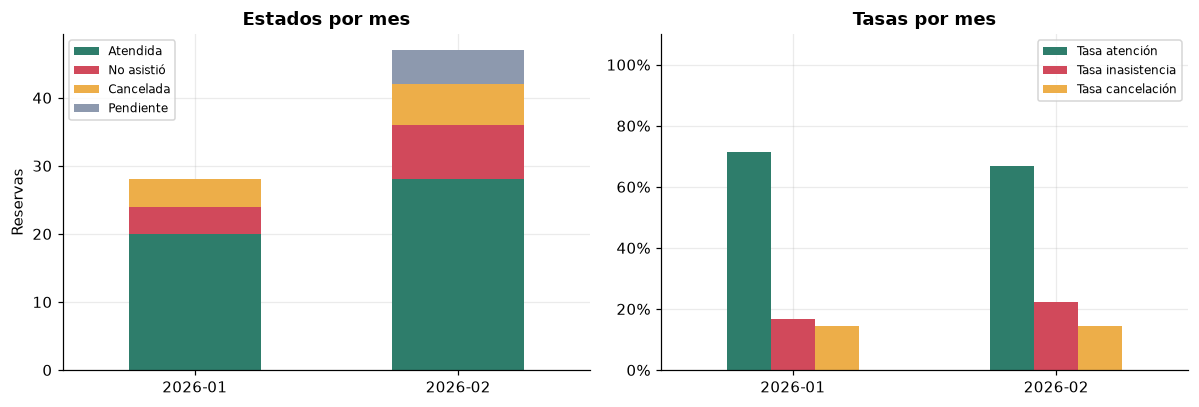

In [8]:
t_mes = tasas(hr, "AnioMes")
display(t_mes.style.format({c: "{:.1%}" for c in t_mes.columns if c.startswith("Tasa")}))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
t_mes[ESTADOS].plot.bar(stacked=True, ax=axs[0], color=[COL_EST[e] for e in ESTADOS], rot=0)
axs[0].set(title="Estados por mes", xlabel="", ylabel="Reservas")
axs[0].legend(loc="upper left", fontsize=8, title=None)
t_mes[["Tasa atención", "Tasa inasistencia", "Tasa cancelación"]].plot.bar(ax=axs[1], rot=0,
        color=[VERDE, COL_EST["No asistió"], COL_EST["Cancelada"]])
axs[1].set(title="Tasas por mes", xlabel="", ylim=(0, 1.1))
axs[1].legend(loc="upper right", fontsize=8, title=None)
axs[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout(); plt.show()

## 4. Canales y horas perdidas (R1, R2, R5)
El canal solo existe desde el 2026-02-04 (`No registrado` = reservas del período base y las que perdieron su canal en cuarentena; `Sin resolver` = etiqueta sin respaldo, p. ej. «WEB»).

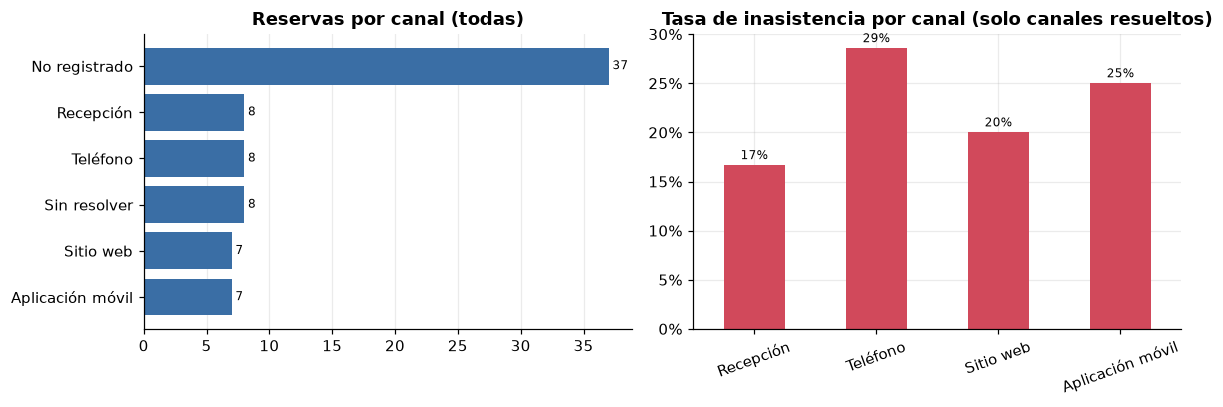

EstadoReserva,Atendida,No asistió,Cancelada,Pendiente,Total,Tasa inasistencia
Canal,,,,,,
Aplicación móvil,3,1,2,1,7,25.0%
Recepción,5,1,1,1,8,16.7%
Sitio web,4,1,1,1,7,20.0%
Teléfono,5,2,1,0,8,28.6%


In [9]:
cn = hr.Canal.value_counts()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].barh(cn.index[::-1], cn.values[::-1], color=AZUL)
for i, v in enumerate(cn.values[::-1]): axs[0].text(v + .3, i, str(v), va="center", fontsize=8)
axs[0].set(title="Reservas por canal (todas)"); axs[0].grid(axis="y", visible=False)

t_can = tasas(hr[hr.Canal.isin(CANALES_OK)], "Canal")
t_can["Tasa inasistencia"].reindex(CANALES_OK).plot.bar(ax=axs[1], color=COL_EST["No asistió"], rot=20)
axs[1].set(title="Tasa de inasistencia por canal (solo canales resueltos)", xlabel="")
axs[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); barras(axs[1], "{:.0%}")
plt.tight_layout(); plt.show()
display(t_can[ESTADOS + ["Total", "Tasa inasistencia"]].style.format({"Tasa inasistencia": "{:.1%}"}))

Cobertura de bloque: 38 de 75 reservas (51%). Las horas perdidas y la utilización solo consideran esas reservas.


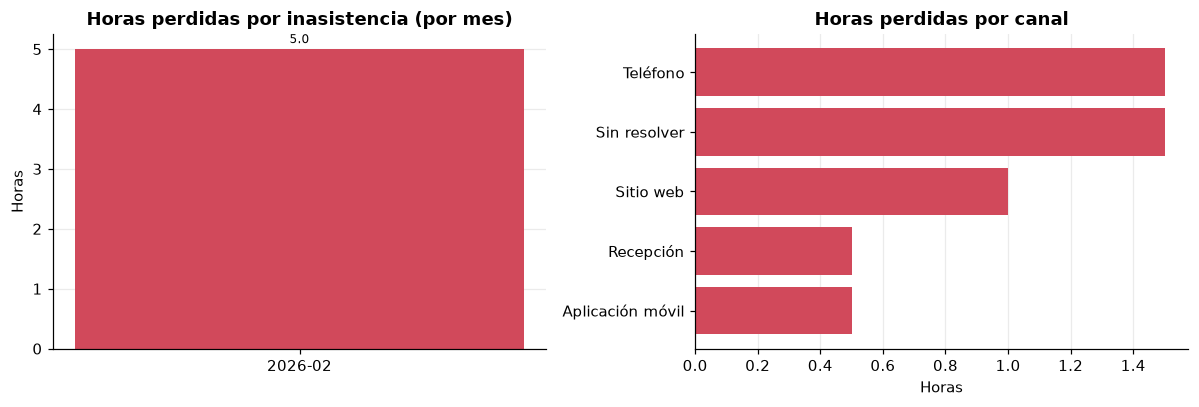

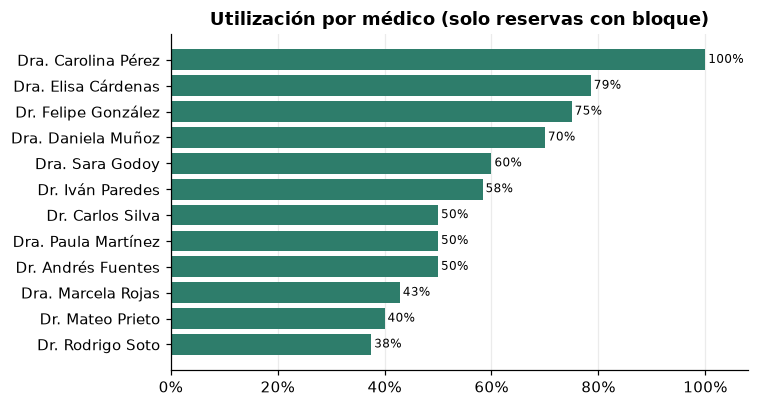

In [10]:
con_bloque = hr[hr.BloqueMinutos.notna()]
print(f"Cobertura de bloque: {len(con_bloque)} de {len(hr)} reservas ({len(con_bloque)/len(hr):.0%}). "
      "Las horas perdidas y la utilización solo consideran esas reservas.")

perd = con_bloque[con_bloque.EstadoReserva == "No asistió"]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
x = (perd.groupby("AnioMes").BloqueMinutos.sum() / 60)
axs[0].bar(x.index, x.values, color=COL_EST["No asistió"]); barras(axs[0], "{:.1f}")
axs[0].set(title="Horas perdidas por inasistencia (por mes)", ylabel="Horas"); axs[0].grid(axis="x", visible=False)

x = (perd.groupby("Canal").BloqueMinutos.sum() / 60).sort_values()
axs[1].barh(x.index, x.values, color=COL_EST["No asistió"])
axs[1].set(title="Horas perdidas por canal", xlabel="Horas"); axs[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

util = con_bloque.groupby("Medico").apply(
    lambda g: g.loc[g.EstadoReserva == "Atendida", "BloqueMinutos"].sum() / g.BloqueMinutos.sum(),
    include_groups=False).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(util.index, util.values, color=VERDE)
ax.set(title="Utilización por médico (solo reservas con bloque)", xlim=(0, 1.08))
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.grid(axis="y", visible=False)
barras(ax, "{:.0%}"); plt.tight_layout(); plt.show()

## 5. Especialidades (D3, RQ02, RQ06, RQ12, RQ18, RQ21, RQ23)

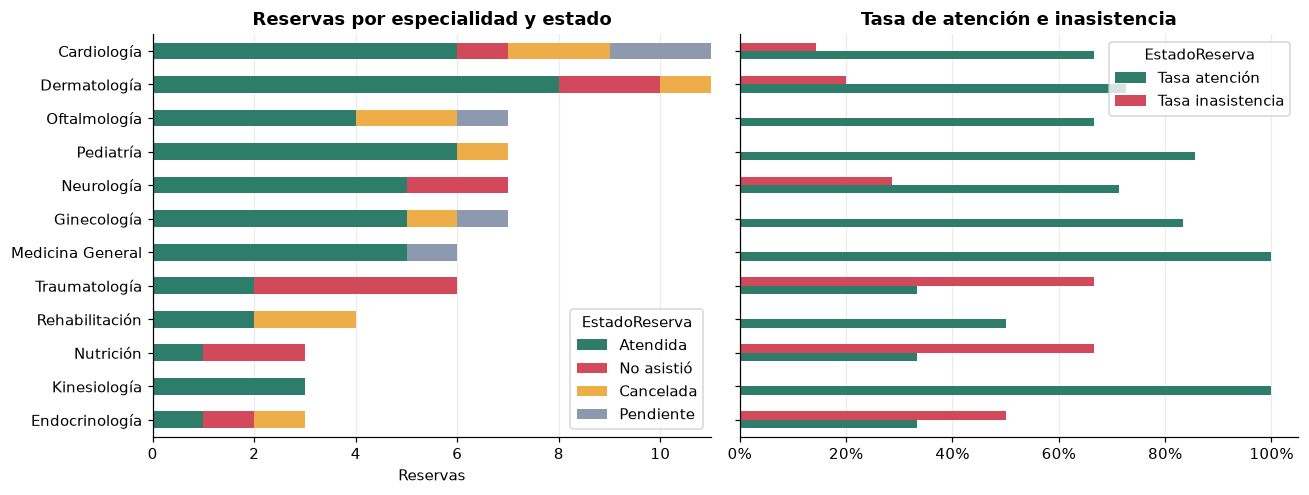

In [11]:
t_esp = tasas(hr, "Especialidad").sort_values("Total")
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
t_esp[ESTADOS].plot.barh(stacked=True, ax=axs[0], color=[COL_EST[e] for e in ESTADOS])
axs[0].set(title="Reservas por especialidad y estado", xlabel="Reservas", ylabel="")
axs[0].grid(axis="y", visible=False)
t_esp[["Tasa atención", "Tasa inasistencia"]].plot.barh(ax=axs[1], color=[VERDE, COL_EST["No asistió"]])
axs[1].set(title="Tasa de atención e inasistencia", xlim=(0, 1.05)); axs[1].grid(axis="y", visible=False)
axs[1].xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout(); plt.show()

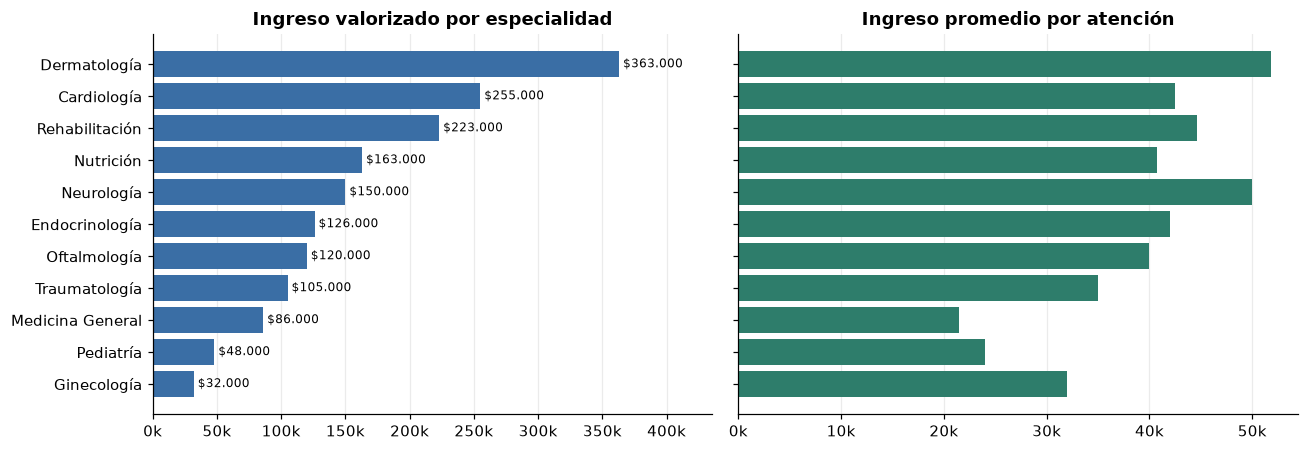

,Médicos,Atenciones
Especialidad,,
Dermatología,2,7
Cardiología,2,6
Rehabilitación,1,5
Medicina General,1,4
Nutrición,1,4
Endocrinología,1,3
Traumatología,1,3
Neurología,1,3
Oftalmología,1,3


In [12]:
ing_esp = hd.groupby("Especialidad").agg(Ingreso=("Importe", "sum"), Atenciones=("AtencionID", "nunique"),
                                         Prestaciones=("Cantidad", "sum"))
ing_esp["Ingreso por atención"] = ing_esp.Ingreso / ing_esp.Atenciones
ing_esp = ing_esp.sort_values("Ingreso")

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
axs[0].barh(ing_esp.index, ing_esp.Ingreso, color=AZUL)
for i, v in enumerate(ing_esp.Ingreso): axs[0].text(v, i, " " + clp(v), va="center", fontsize=8)
axs[0].set(title="Ingreso valorizado por especialidad"); axs[0].grid(axis="y", visible=False)
axs[0].xaxis.set_major_formatter(lambda v, _: f"{v/1e3:,.0f}k"); axs[0].margins(x=.2)
axs[1].barh(ing_esp.index, ing_esp["Ingreso por atención"], color=VERDE)
axs[1].set(title="Ingreso promedio por atención"); axs[1].grid(axis="y", visible=False)
axs[1].xaxis.set_major_formatter(lambda v, _: f"{v/1e3:,.0f}k")
plt.tight_layout(); plt.show()

carga_esp = med.groupby("Especialidad").size().rename("Médicos").to_frame().join(ing_esp[["Atenciones"]], how="outer").fillna(0).astype(int)
display(carga_esp.sort_values("Atenciones", ascending=False))

## 6. Médicos (M1–M5, RQ09–RQ11, RQ19)

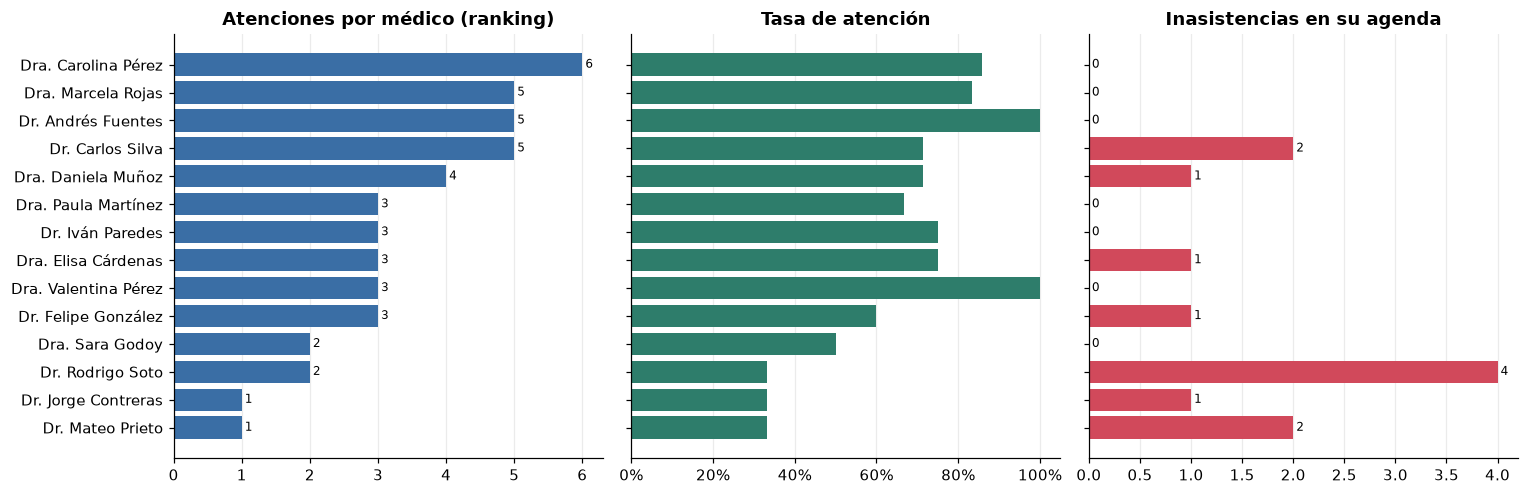

,Total,Atendida,No asistió,Cancelada,Pendiente,Tasa atención,Ingreso,Ingreso promedio por atención
Medico,,,,,,,,
Dra. Carolina Pérez,7,6,0,1,0,86%,$164.000,$32.800
Dr. Andrés Fuentes,6,5,0,0,1,100%,$128.000,$32.000
Dra. Daniela Muñoz,7,5,1,1,0,71%,$179.000,$44.750
Dra. Marcela Rojas,7,5,0,1,1,83%,$132.000,$33.000
Dr. Carlos Silva,7,5,2,0,0,71%,$180.000,$45.000
Dra. Paula Martínez,7,4,0,2,1,67%,$120.000,$40.000
Dra. Valentina Pérez,3,3,0,0,0,100%,$102.000,$34.000
Dra. Elisa Cárdenas,4,3,1,0,0,75%,$107.000,$53.500
Dr. Iván Paredes,5,3,0,1,1,75%,$150.000,$50.000


In [13]:
t_med = tasas(hr, "Medico")
at = hr.groupby("Medico").AtencionID.count().rename("Atenciones")
ingm = hd.groupby("Medico").agg(Ingreso=("Importe", "sum"), n=("AtencionID", "nunique"))
ingm["Ingreso promedio por atención"] = ingm.Ingreso / ingm.n
tabla_med = t_med.join(at).join(ingm[["Ingreso", "Ingreso promedio por atención"]])

fig, axs = plt.subplots(1, 3, figsize=(14, 4.6), sharey=True)
a = tabla_med.Atenciones.sort_values()
axs[0].barh(a.index, a.values, color=AZUL); barras(axs[0])
axs[0].set(title="Atenciones por médico (ranking)"); axs[0].grid(axis="y", visible=False)
b = tabla_med["Tasa atención"].reindex(a.index)
axs[1].barh(b.index, b.values, color=VERDE); axs[1].set(title="Tasa de atención", xlim=(0, 1.05))
axs[1].xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); axs[1].grid(axis="y", visible=False)
c = tabla_med["No asistió"].reindex(a.index)
axs[2].barh(c.index, c.values, color=COL_EST["No asistió"]); barras(axs[2])
axs[2].set(title="Inasistencias en su agenda"); axs[2].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

display(tabla_med[["Total", "Atendida", "No asistió", "Cancelada", "Pendiente", "Tasa atención",
                   "Ingreso", "Ingreso promedio por atención"]]
        .sort_values("Atendida", ascending=False)
        .style.format({"Tasa atención": "{:.0%}", "Ingreso": clp, "Ingreso promedio por atención": clp}))

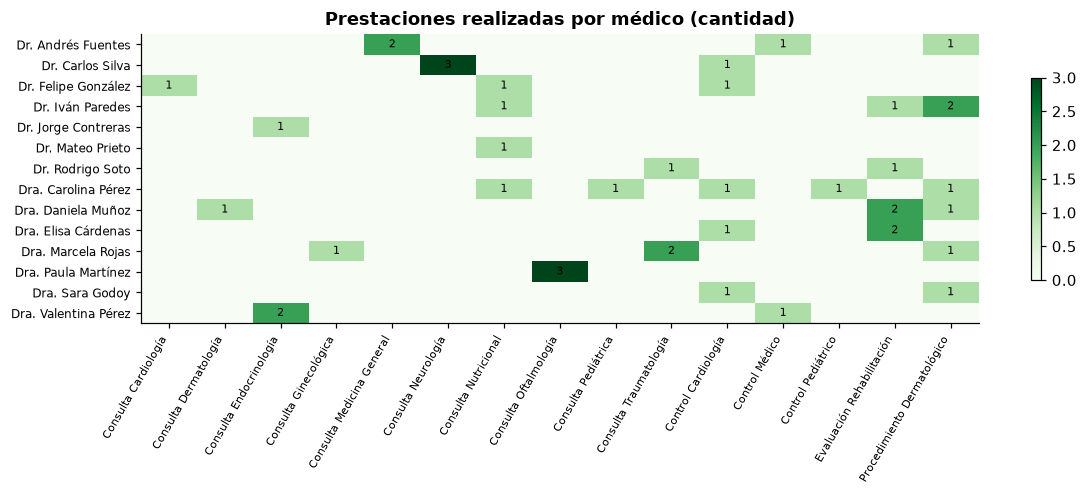

In [14]:
# M3: qué prestaciones realiza más cada médico (cantidad)
mp = hd.pivot_table(index="Medico", columns="Prestacion", values="Cantidad", aggfunc="sum", fill_value=0)
fig, ax = plt.subplots(figsize=(11, 4.6))
im = ax.imshow(mp.values, cmap="Greens", aspect="auto")
ax.set_xticks(range(mp.shape[1]), mp.columns, rotation=60, ha="right", fontsize=7)
ax.set_yticks(range(mp.shape[0]), mp.index, fontsize=8)
for i in range(mp.shape[0]):
    for j in range(mp.shape[1]):
        if mp.values[i, j]: ax.text(j, i, int(mp.values[i, j]), ha="center", va="center", fontsize=7)
ax.set(title="Prestaciones realizadas por médico (cantidad)"); ax.grid(False)
plt.colorbar(im, ax=ax, shrink=.7); plt.tight_layout(); plt.show()

## 7. Pacientes (P1–P5, RQ13–RQ16)

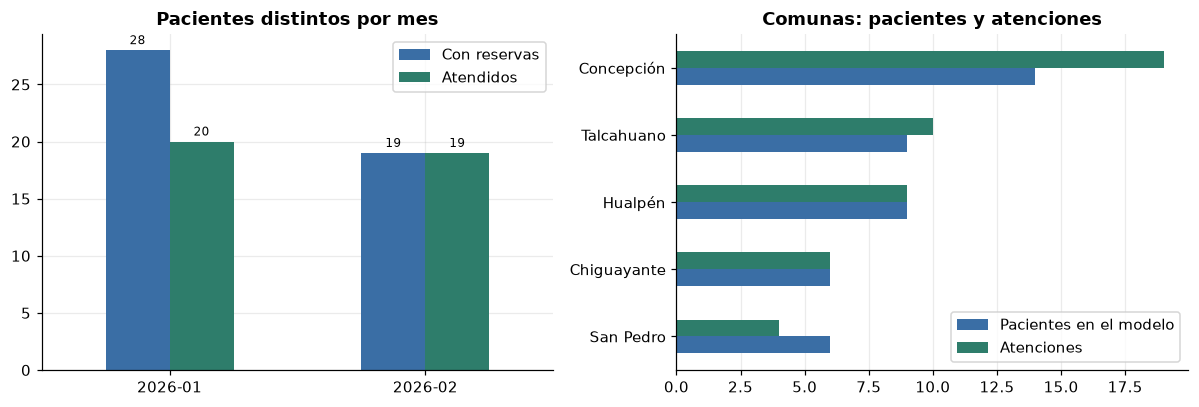

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
pm = pd.DataFrame({
    "Con reservas": hr.groupby("AnioMes").PacienteID.nunique(),
    "Atendidos": hr[hr.EstadoReserva == "Atendida"].groupby("AnioMes").PacienteID.nunique()})
pm.plot.bar(ax=axs[0], rot=0, color=[AZUL, VERDE]); barras(axs[0])
axs[0].set(title="Pacientes distintos por mes", xlabel="")

cm = pd.DataFrame({
    "Pacientes en el modelo": pac.groupby("Comuna").size(),
    "Atenciones": hr[hr.EstadoReserva == "Atendida"].groupby("Comuna").size()}).fillna(0).sort_values("Atenciones")
cm.plot.barh(ax=axs[1], color=[AZUL, VERDE]); axs[1].set(title="Comunas: pacientes y atenciones", ylabel="")
axs[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

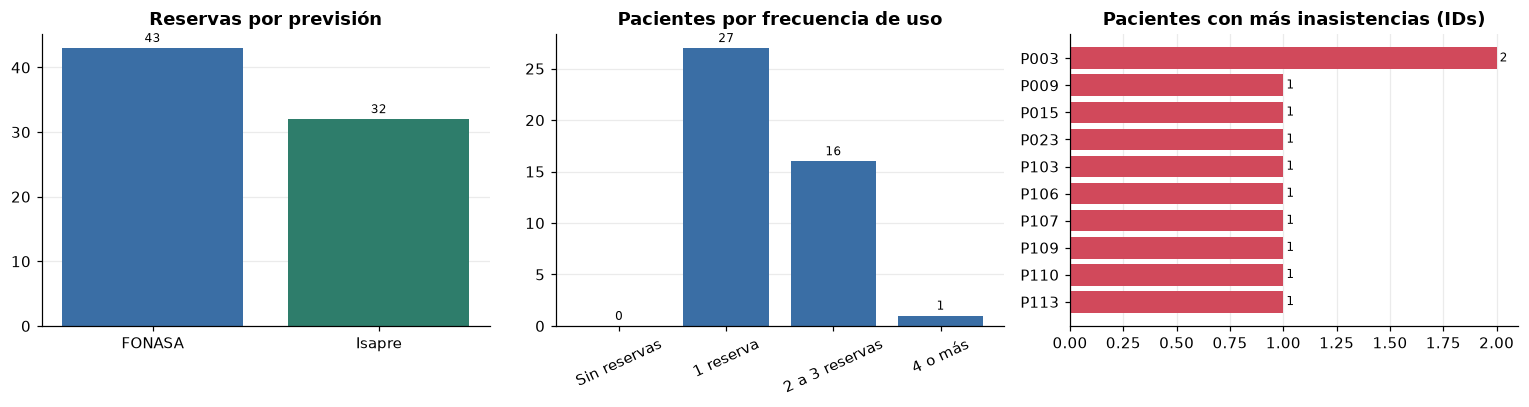

Reservas por paciente (promedio): 1.7


In [16]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
pv = hr.groupby("Prevision").size()
axs[0].bar(pv.index, pv.values, color=[AZUL, VERDE]); barras(axs[0])
axs[0].set(title="Reservas por previsión"); axs[0].grid(axis="x", visible=False)

frec = hr.groupby("PacienteID").size().reindex(pac.PacienteID, fill_value=0)
tramo = pd.cut(frec, bins=[-1, 0, 1, 3, np.inf],
               labels=["Sin reservas", "1 reserva", "2 a 3 reservas", "4 o más"]).value_counts().sort_index()
axs[1].bar(tramo.index, tramo.values, color=AZUL); barras(axs[1])
axs[1].set(title="Pacientes por frecuencia de uso"); axs[1].tick_params(axis="x", rotation=25)
axs[1].grid(axis="x", visible=False)

ina = (hr[hr.EstadoReserva == "No asistió"].groupby("PacienteID").size()
       .sort_values(ascending=False).head(10)[::-1])
axs[2].barh(ina.index, ina.values, color=COL_EST["No asistió"]); barras(axs[2])
axs[2].set(title="Pacientes con más inasistencias (IDs)"); axs[2].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print("Reservas por paciente (promedio):", round(len(hr) / hr.PacienteID.nunique(), 2))

## 8. Ingresos (D2, RQ17–RQ20)

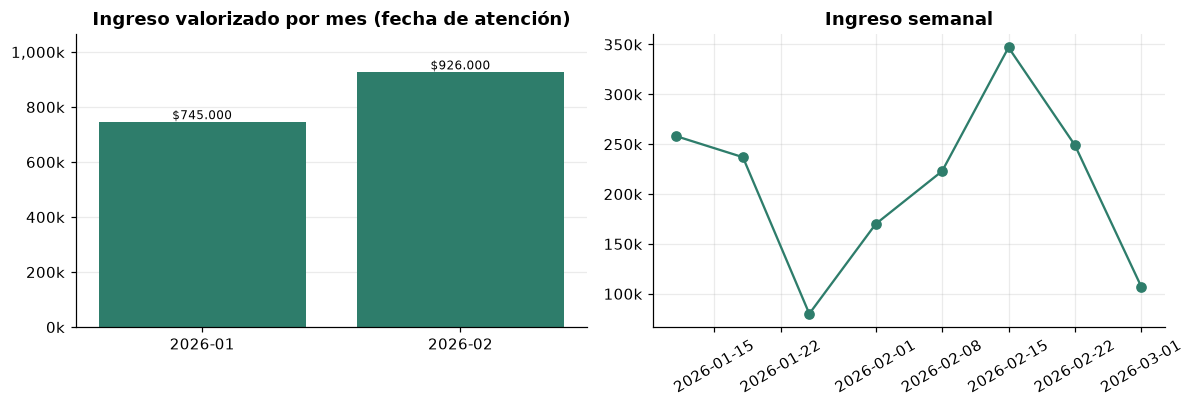

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
im_ = hd.groupby("AnioMes").Importe.sum()
axs[0].bar(im_.index, im_.values, color=VERDE)
for i, v in enumerate(im_.values): axs[0].text(i, v, clp(v), ha="center", va="bottom", fontsize=8)
axs[0].set(title="Ingreso valorizado por mes (fecha de atención)"); axs[0].grid(axis="x", visible=False)
axs[0].yaxis.set_major_formatter(lambda v, _: f"{v/1e3:,.0f}k"); axs[0].margins(y=.15)

sem = hd.set_index("FechaAtencion").Importe.resample("W-SUN").sum()
axs[1].plot(sem.index, sem.values, marker="o", color=VERDE)
axs[1].set(title="Ingreso semanal"); axs[1].tick_params(axis="x", rotation=30)
axs[1].yaxis.set_major_formatter(lambda v, _: f"{v/1e3:,.0f}k")
plt.tight_layout(); plt.show()

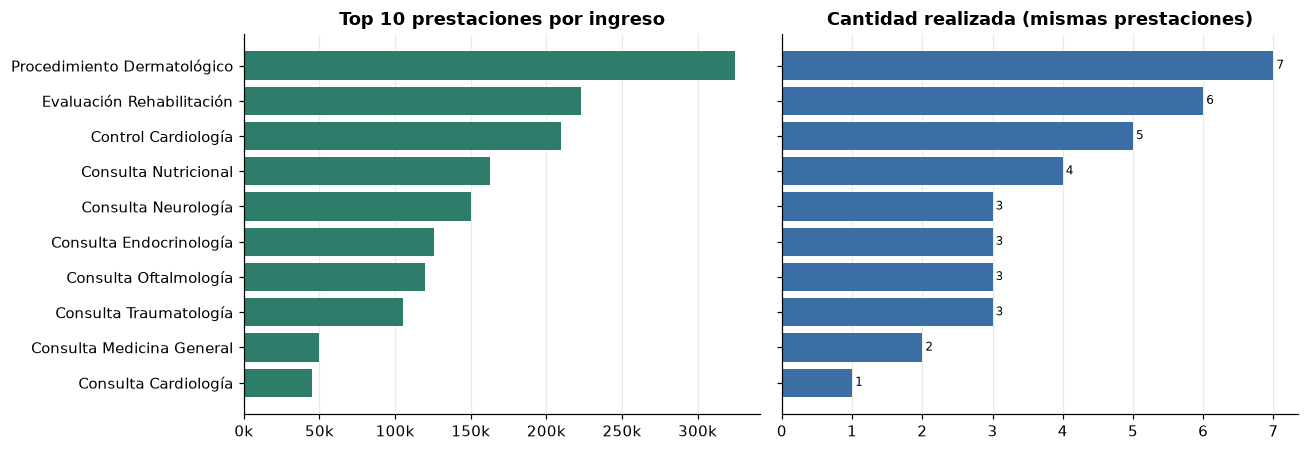

Diferencia Importe vs Cantidad x ValorUnitario: 0
Detalles con ValorUnitario distinto de la tarifa maestra: 12 de 41


In [18]:
pr = hd.groupby("Prestacion").agg(Ingreso=("Importe", "sum"), Cantidad=("Cantidad", "sum")).sort_values("Ingreso")
top = pr.tail(10)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
axs[0].barh(top.index, top.Ingreso, color=VERDE); axs[0].set(title="Top 10 prestaciones por ingreso")
axs[0].xaxis.set_major_formatter(lambda v, _: f"{v/1e3:,.0f}k"); axs[0].grid(axis="y", visible=False)
axs[1].barh(top.index, top.Cantidad, color=AZUL); axs[1].set(title="Cantidad realizada (mismas prestaciones)")
axs[1].grid(axis="y", visible=False); barras(axs[1])
plt.tight_layout(); plt.show()

# Control: el importe del modelo coincide con Cantidad x ValorUnitario
dif = (hd.Importe - hd.Cantidad * hd.ValorUnitario).abs().sum()
print("Diferencia Importe vs Cantidad x ValorUnitario:", dif)
# Control: tarifa del hecho vs tarifa maestra (informativo; no se corrige)
chk = hd.merge(pre[["PrestacionID", "Tarifa_maestra"]], on="PrestacionID", validate="m:1")
dist = chk[chk.ValorUnitario != chk.Tarifa_maestra]
print(f"Detalles con ValorUnitario distinto de la tarifa maestra: {len(dist)} de {len(chk)}")

## 9. Calidad de datos del ETL (B1–B5)

,Tabla,Entrada,Aceptadas,Duplicados,Rechazadas,Cuadra,Claves_unicas_en_aceptadas
0,Pacientes,48,44,0,4,True,True
1,Médicos,16,14,0,2,True,True
2,Prestaciones,20,19,0,1,True,True
3,Reservas,80,75,1,4,True,True
4,Canales/bloques,52,38,1,13,True,True
5,Atenciones,49,46,1,2,True,True
6,Detalle,50,41,1,8,True,True


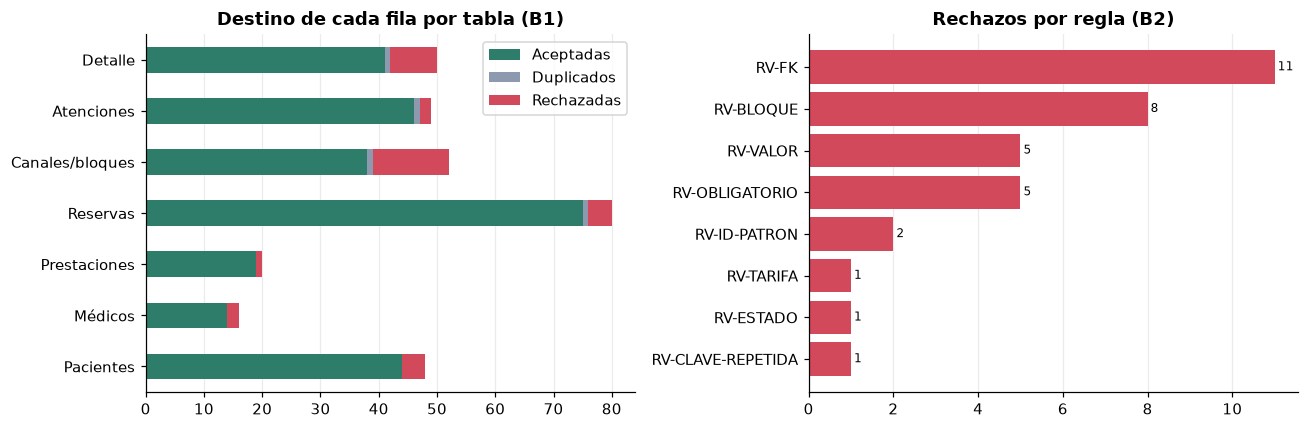

In [19]:
ctl = MODELO / "control"
carga = pd.read_csv(ctl / "control_carga.csv")
rech = pd.read_csv(ctl / "rechazos.csv")
display(carga)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
c = carga.set_index("Tabla")[["Aceptadas", "Duplicados", "Rechazadas"]]
c.plot.barh(stacked=True, ax=axs[0], color=[VERDE, "#8D99AE", COL_EST["No asistió"]])
axs[0].set(title="Destino de cada fila por tabla (B1)", ylabel=""); axs[0].grid(axis="y", visible=False)
r = rech.groupby("Regla").size().sort_values()
axs[1].barh(r.index, r.values, color=COL_EST["No asistió"]); barras(axs[1])
axs[1].set(title="Rechazos por regla (B2)"); axs[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [20]:
print("Etiquetas sin resolver (B3):")
display(pd.read_csv(ctl / "no_resueltos.csv"))
print("Reservas Atendidas sin atención registrada (para reconciliación):")
display(pd.read_csv(ctl / "reservas_atendidas_sin_atencion.csv"))
print("Integridad referencial (B5):")
display(pd.read_csv(ctl / "control_integridad.csv"))
print("Muestra de rechazos:")
display(rech.drop(columns="Fila_origen").head(15))

Etiquetas sin resolver (B3):


,Entidad,EtiquetaRaw,Filas,EspecialidadID,Canonica,Resuelta,Motivo
0,Canal,Kiosco,1,NaN,NaN,False,Sin catálogo que la respalde
1,Canal,[WEB ],8,NaN,NaN,False,Sin catálogo que la respalde
2,Especialidad,NaN,1,NaN,NaN,False,ID faltante
3,Especialidad,Hematología,1,E99,NaN,False,E99 no existe en maestros
4,Estado,Confirmada,1,NaN,NaN,False,Fuera de catálogo: no se interpreta


Reservas Atendidas sin atención registrada (para reconciliación):


,ReservaID,FechaReserva,MedicoID,PacienteID
0,R0146,2026-02-26,M006,P112
1,R0148,2026-02-27,M008,P114


Integridad referencial (B5):


,Relacion,Huerfanos,OK
0,HechoReservas.FechaReserva -> DimFecha,0,True
1,HechoReservas.PacienteID -> DimPaciente,0,True
2,HechoReservas.MedicoID -> DimMedico,0,True
3,HechoDetalle.FechaAtencion -> DimFecha,0,True
4,HechoDetalle.PacienteID -> DimPaciente,0,True
5,HechoDetalle.MedicoID -> DimMedico,0,True
6,HechoDetalle.PrestacionID -> DimPrestacion,0,True
7,HechoDetalle.AtencionID -> HechoReservas.Atenc...,0,True


Muestra de rechazos:


,Fuente,Clave,Campo,Regla,ValorRaw,Motivo
0,01_PACIENTES,P031,"Nombre, Comuna, FechaNacimiento, Prevision, Sexo",RV-OBLIGATORIO,NaN,"Campos obligatorios nulos: Nombre, Comuna, Fec..."
1,01_PACIENTES,P032,"Nombre, Comuna, FechaNacimiento, Prevision, Sexo",RV-OBLIGATORIO,NaN,"Campos obligatorios nulos: Nombre, Comuna, Fec..."
2,01_PACIENTES,P033,"Nombre, Comuna, FechaNacimiento, Prevision, Sexo",RV-OBLIGATORIO,NaN,"Campos obligatorios nulos: Nombre, Comuna, Fec..."
3,A01_PACIENTES,P115,"Nombre, Comuna, FechaNacimiento, Sexo",RV-OBLIGATORIO,NaN,"Campos obligatorios nulos: Nombre, Comuna, Fec..."
4,A02_MEDICOS,M015,EspecialidadID,RV-FK,E99,EspecialidadID=E99 no existe en especialidades
5,A02_MEDICOS,M016,Medico,RV-OBLIGATORIO,NaN,Campos obligatorios nulos: Medico
6,A04_PRESTACIONES,PR020,Valor,RV-TARIFA,NaN,Valor nulo o no numérico (tarifa ausente: no s...
7,A05_RESERVAS,R0109,PacienteID,RV-FK,NaN,PacienteID nulo: FK obligatoria
8,A05_RESERVAS,R0119,MedicoID,RV-FK,M099,MedicoID=M099 no existe en DimMedico
9,A05_RESERVAS,R0129,EstadoReserva,RV-ESTADO,Confirmada,EstadoReserva fuera del catálogo acordado de e...


## 10. Hallazgos automáticos
Resumen calculado con los datos actuales; sirve de borrador para la sección de conclusiones y recomendaciones.

In [21]:
def top(s):  # (nombre, valor) del máximo
    return s.idxmax(), s.max()

esp_dem = hr.groupby("Especialidad").size()
esp_ing = hd.groupby("Especialidad").Importe.sum()
dia = hr.groupby("NombreDia").size()
med_at = hr.groupby("Medico").AtencionID.count()
canal_ok = hr[hr.Canal.isin(CANALES_OK)].groupby("Canal").size()
t_c = tasas(hr[hr.Canal.isin(CANALES_OK)], "Canal")["Tasa inasistencia"]

lineas = [
    f"- Se registran {len(hr)} reservas; {est['Atendida']} terminan en atención ({est['Atendida']/len(hr):.0%} del total).",
    f"- Tasa de inasistencia global: {est['No asistió']/(est['Atendida']+est['No asistió']):.1%}; "
    f"cancelación: {est['Cancelada']/resueltas:.1%}; quedan {est['Pendiente']} reservas pendientes.",
    f"- Especialidad más solicitada: {top(esp_dem)[0]} ({top(esp_dem)[1]} reservas). Mayor ingreso: {top(esp_ing)[0]} ({clp(top(esp_ing)[1])}).",
    f"- Día con más demanda: {top(dia)[0]} ({top(dia)[1]} reservas).",
    f"- Médico con más atenciones: {top(med_at)[0]} ({top(med_at)[1]}).",
    f"- Canal con más reservas (resueltos): {top(canal_ok)[0]} ({top(canal_ok)[1]}); "
    f"mayor inasistencia: {top(t_c.dropna())[0]} ({top(t_c.dropna())[1]:.0%}).",
    f"- Ingreso valorizado total: {clp(hd.Importe.sum())} (no es dinero cobrado).",
    f"- Calidad: {len(rech)} filas rechazadas por reglas del ETL; "
    f"{(hr.Canal == 'No registrado').sum()} reservas sin canal registrado.",
]
print("\n".join(lineas))

- Se registran 75 reservas; 48 terminan en atención (64% del total).
- Tasa de inasistencia global: 20.0%; cancelación: 14.3%; quedan 5 reservas pendientes.
- Especialidad más solicitada: Cardiología (11 reservas). Mayor ingreso: Dermatología ($363.000).
- Día con más demanda: Lunes (13 reservas).
- Médico con más atenciones: Dra. Carolina Pérez (6).
- Canal con más reservas (resueltos): Recepción (8); mayor inasistencia: Teléfono (29%).
- Ingreso valorizado total: $1.671.000 (no es dinero cobrado).
- Calidad: 34 filas rechazadas por reglas del ETL; 37 reservas sin canal registrado.
